# groupcast_mcr_baseline_eval — analysis

Single-hop (no-relay) baseline for the NR-V2X mode-2 groupcast platoon study. The system model is shared with `relay_l2id_compare` / `relay_storm_eval` (mu=2, 10 subchannels, MCS-14, moving platoon, MCD gate). This notebook aggregates the per-cell results written by `aggregate_baseline.py` and produces the headline figures.

Inputs (expected):
- `<results>/all_cells.csv` — master per-cell aggregate (rows = one per (N, harq, traffic, speed, ivd, mcr)).
- `<results>/cells/<cellTag>/per_seed.csv` — per-(seed, UE) detail.

Outputs:
- Headline figures (saved as PNG next to this notebook).
- Summary tables saved as CSV.

In [1]:
import os, glob, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Resolve results directory relative to this notebook.
NB_DIR = Path.cwd()
RESULTS = NB_DIR / "results"
# Pick the first directory that has an all_cells.csv (the master roll-up).
if not (RESULTS / "all_cells.csv").exists():
    cand = NB_DIR.parent / "results"
    if (cand / "all_cells.csv").exists():
        RESULTS = cand
    elif (NB_DIR / "results_smoke" / "all_cells.csv").exists():
        RESULTS = NB_DIR / "results_smoke"
    else:
        # Try the path passed by build_notebook if present
        RESULTS = NB_DIR
print(f"Using results dir: {RESULTS}")
all_cells_csv = RESULTS / "all_cells.csv"
if not all_cells_csv.exists():
    raise FileNotFoundError(f"Missing {all_cells_csv}. Run aggregate_baseline.py first.")
df = pd.read_csv(all_cells_csv)
print(f"Loaded {len(df)} cell rows")
print("Columns:", list(df.columns))
df.head()

Using results dir: /Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/groupcast_mcr_baseline_eval/results
Loaded 812 cell rows
Columns: ['N', 'speed', 'ivd', 'mcr_m', 'mcr_label', 'harq', 'traffic', 'n_seeds', 'n_ue_rows', 'prr_mean', 'prr_median', 'prr_p5', 'prr_p95', 'prr_std', 'prr_worst_mean', 'pir_mean_ms', 'pir_median_ms', 'pir_p5_ms', 'pir_p95_ms', 'pir_std_ms', 'pir_worst_ms_mean', 'aoi_mean_ms', 'aoi_median_ms', 'aoi_p5_ms', 'aoi_p95_ms', 'aoi_worst_ms_mean', 'hd_total', 'rc_total', 'ce_total', 'corrupt_total', 'ch_occupancy_mean', 'hop1_retx_total', 'subch_slots_used_total', 'subch_slots_per_pkt_mean']


,N,speed,ivd,mcr_m,mcr_label,harq,traffic,n_seeds,n_ue_rows,prr_mean,...,aoi_p95_ms,aoi_worst_ms_mean,hd_total,rc_total,ce_total,corrupt_total,ch_occupancy_mean,hop1_retx_total,subch_slots_used_total,subch_slots_per_pkt_mean
0,10,100,29,115.5,admit_4,1,onoff,5,45,0.982679,...,61.6235,55.88212,0,0,118,118,0.002500,2880,10170,4.52
1,10,100,29,115.5,admit_4,2,onoff,5,45,0.945630,...,84.3391,81.08252,0,0,111,111,0.001084,0,4410,1.96
2,10,100,29,144.5,admit_5,1,onoff,5,45,0.982457,...,62.1269,58.86828,0,0,123,123,0.002500,2880,10170,4.52
3,10,100,29,144.5,admit_5,2,onoff,5,45,0.949667,...,75.2001,71.30438,0,0,104,104,0.001084,0,4410,1.96
4,10,100,29,14.0,admit_0,1,onoff,5,45,0.984704,...,57.3160,53.87664,0,0,116,116,0.002500,2880,10170,4.52


## Section 1 — PRR vs MCR grid (heatmap, faceted by N and HARQ)

For each (N, harq), plot PRR_worst (lower is worse) as a function of MCR distance. One curve per (speed, ivd) operating point. This is the headline figure for H1: as MCR grows from `k*IVD - 0.5` to `(k+1)*IVD - 0.5`, follower k joins the feedback group, so PRR_worst (taken over followers 1..k) should improve sharply when MCR crosses `k*IVD`.

Saved /Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/groupcast_mcr_baseline_eval/results/fig1_prr_vs_mcr.png


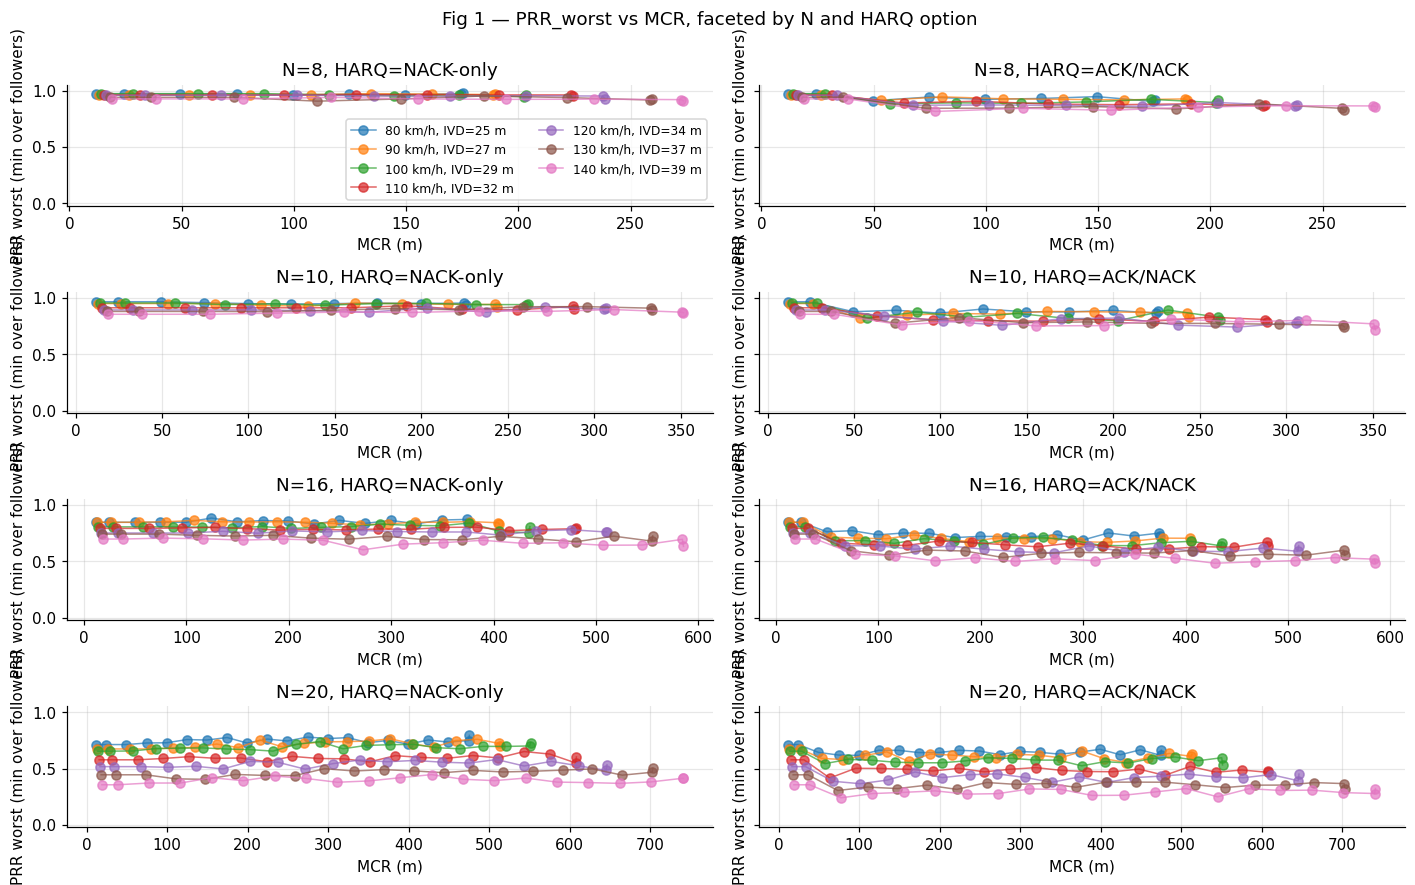

In [2]:
ns = sorted(df["N"].unique())
harqs = sorted(df["harq"].unique())
fig, axes = plt.subplots(len(ns), len(harqs), figsize=(13, 8), sharey=True, squeeze=False)
for i, N in enumerate(ns):
    for j, harq in enumerate(harqs):
        ax = axes[i, j]
        sub = df[(df["N"] == N) & (df["harq"] == harq)]
        for (spd, ivd), g in sub.groupby(["speed", "ivd"]):
            g = g.sort_values("mcr_m")
            ax.plot(g["mcr_m"], g["prr_worst_mean"], marker="o",
                    label=f"{spd} km/h, IVD={ivd} m", alpha=0.7, linewidth=1)
        ax.set_title(f"N={N}, HARQ={'NACK-only' if harq==1 else 'ACK/NACK'}")
        ax.set_xlabel("MCR (m)")
        ax.set_ylabel("PRR worst (min over followers)")
        ax.set_ylim(-0.02, 1.05)
        if i == 0 and j == 0:
            ax.legend(fontsize=8, ncol=2, loc="lower right")
fig.suptitle("Fig 1 — PRR_worst vs MCR, faceted by N and HARQ option", y=1.00, fontsize=12)
fig.tight_layout()
out = RESULTS / "fig1_prr_vs_mcr.png"
fig.savefig(out, bbox_inches="tight")
print(f"Saved {out}")
plt.show()

## Section 2 — PIR worst vs N (line plot)

PIR worst (max over followers) vs platoon size N, one line per (harq, traffic). Higher N means longer tail, longer delays, and more contention; PIR should grow roughly with the tail length × RRI.

Saved /Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/groupcast_mcr_baseline_eval/results/fig2_pir_vs_N.png


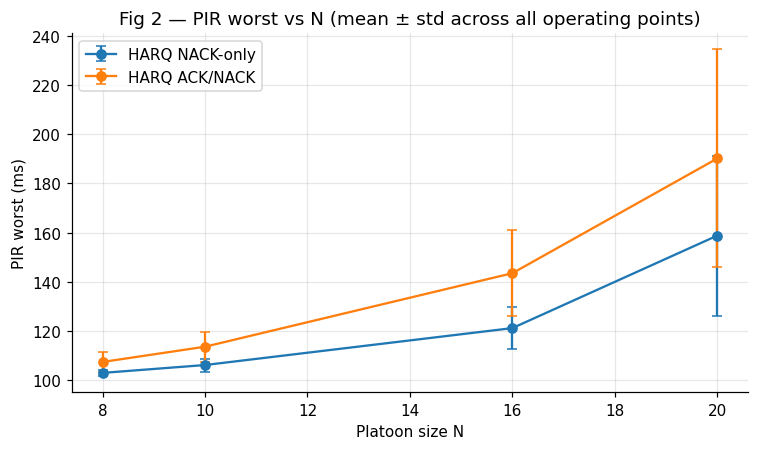

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for harq in harqs:
    sub = df[df["harq"] == harq]
    g = sub.groupby("N")["pir_worst_ms_mean"].agg(["mean", "std"]).reset_index()
    ax.errorbar(g["N"], g["mean"], yerr=g["std"], marker="o",
                label=f"HARQ {'NACK-only' if harq==1 else 'ACK/NACK'}", capsize=3)
ax.set_xlabel("Platoon size N")
ax.set_ylabel("PIR worst (ms)")
ax.set_title("Fig 2 — PIR worst vs N (mean ± std across all operating points)")
ax.legend()
fig.tight_layout()
out = RESULTS / "fig2_pir_vs_N.png"
fig.savefig(out, bbox_inches="tight")
print(f"Saved {out}")
plt.show()

## Section 3 — AoI mean vs MCR (line plot)

AoI mean (trapezoidal sawtooth area / window) vs MCR, faceted by N. AoI falls when more receivers are in feedback range (more reTX opportunities reduce gaps).

Saved /Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/groupcast_mcr_baseline_eval/results/fig3_aoi_vs_mcr.png


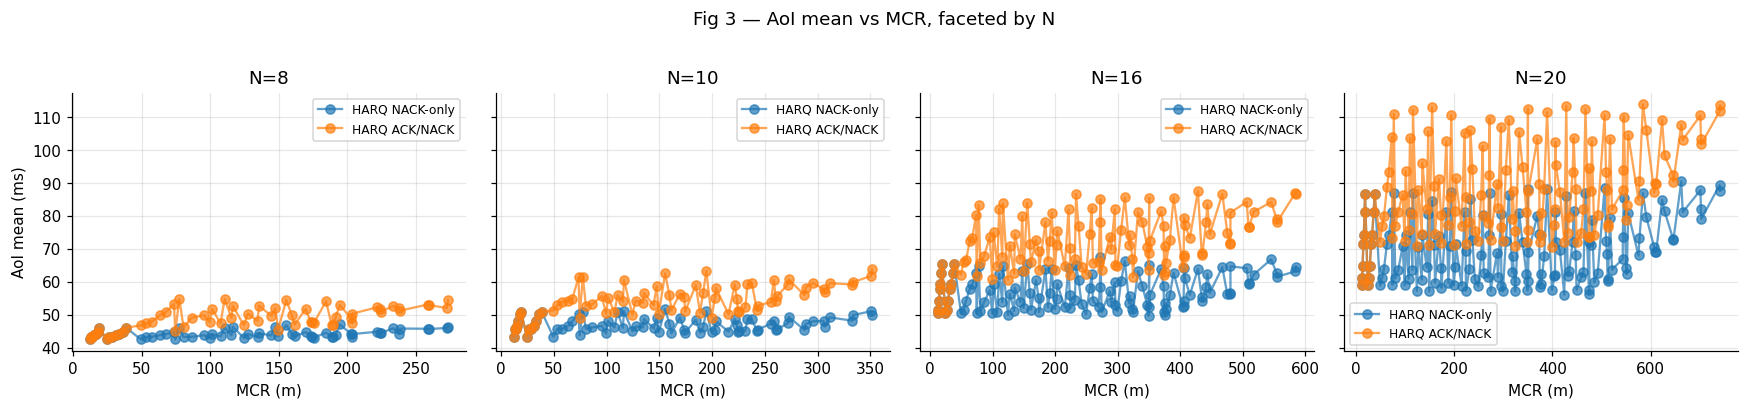

In [4]:
fig, _axes = plt.subplots(1, len(ns), figsize=(4 * len(ns), 3.6), sharey=True, squeeze=False)
axes = _axes[0]
for i, N in enumerate(ns):
    ax = axes[i]
    sub = df[df["N"] == N]
    for harq in harqs:
        g = sub[sub["harq"] == harq].sort_values("mcr_m")
        ax.plot(g["mcr_m"], g["aoi_mean_ms"], marker="o",
                label=f"HARQ {'NACK-only' if harq==1 else 'ACK/NACK'}", alpha=0.7)
    ax.set_title(f"N={N}")
    ax.set_xlabel("MCR (m)")
    if i == 0:
        ax.set_ylabel("AoI mean (ms)")
    ax.legend(fontsize=8)
fig.suptitle("Fig 3 — AoI mean vs MCR, faceted by N", y=1.02)
fig.tight_layout()
out = RESULTS / "fig3_aoi_vs_mcr.png"
fig.savefig(out, bbox_inches="tight")
print(f"Saved {out}")
plt.show()

## Section 4 — PSSCH/PSFCH collision attribution (stacked bar)

Per cell, the aggregator sums `hd_count` (half-duplex deaf slots), `rc_count` (resource-collision corrupt), `ce_count` (channel-error / fade). For each N we show how the partition changes as MCR grows. This is the headline figure for the new collision instrumentation: H4 is that MCR ≥ (N-1)*IVD keeps all followers in feedback range, so collisions inside the platoon are dominated by RC; below that, hidden-node / out-of-MCR effects should appear.

Saved /Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/groupcast_mcr_baseline_eval/results/fig4_collisions_vs_mcr.png


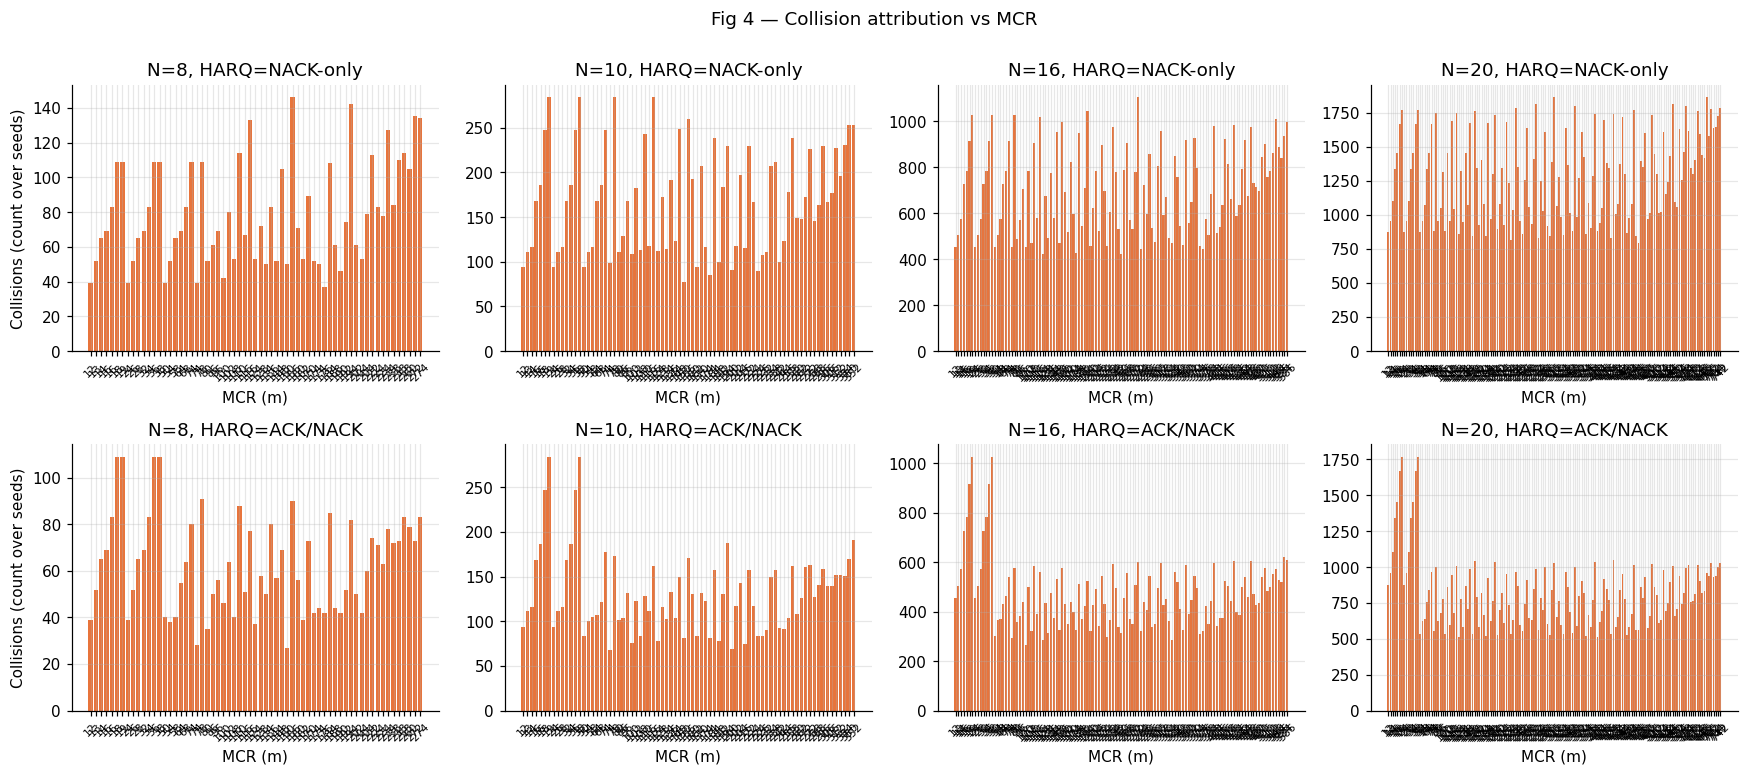

In [5]:
fig, _axes = plt.subplots(2, len(ns), figsize=(4 * len(ns), 7), sharex=False, squeeze=False)
axes = _axes
for j, N in enumerate(ns):
    for i, harq in enumerate(harqs):
        ax = axes[i, j]
        sub = df[(df["N"] == N) & (df["harq"] == harq)].sort_values("mcr_m")
        if len(sub) == 0:
            ax.set_title(f"N={N}, h={harq} (no data)")
            continue
        x = np.arange(len(sub))
        hd = sub["hd_total"].fillna(0)
        rc = sub["rc_total"].fillna(0)
        ce = sub["ce_total"].fillna(0)
        ax.bar(x, hd, label="HD (half-duplex)", color="#88c4a8")
        ax.bar(x, rc, bottom=hd, label="RC (resource collision)", color="#5b8def")
        ax.bar(x, ce, bottom=hd + rc, label="CE (channel error)", color="#e8743b")
        ax.set_xticks(x)
        ax.set_xticklabels([f"{m:.0f}" for m in sub["mcr_m"]], rotation=45, fontsize=7)
        ax.set_xlabel("MCR (m)")
        if j == 0:
            ax.set_ylabel("Collisions (count over seeds)")
        ax.set_title(f"N={N}, HARQ={'NACK-only' if harq==1 else 'ACK/NACK'}")
fig.suptitle("Fig 4 — Collision attribution vs MCR", y=1.00)
fig.tight_layout()
out = RESULTS / "fig4_collisions_vs_mcr.png"
fig.savefig(out, bbox_inches="tight")
print(f"Saved {out}")
plt.show()

## Section 5 — MCR-coverage sweep: PRR_worst(k) at MCR = k*IVD - 0.5

For each (N, speed, ivd, harq), isolate the cells at `mcr_label = admit_k` (k = 1..N-1) and plot PRR_worst as a function of k. The hypothesis: PRR_worst tracks the worst-UE PRR at MCR = k*IVD - 0.5, which admits exactly k followers. This should be a near-monotone INCREASE in k (more followers in feedback range ⇒ higher worst-case PRR), and the step size should reveal when MCD gate becomes bottleneck vs when channel errors dominate.

Saved /Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/groupcast_mcr_baseline_eval/results/fig5_prr_worst_vs_k.png


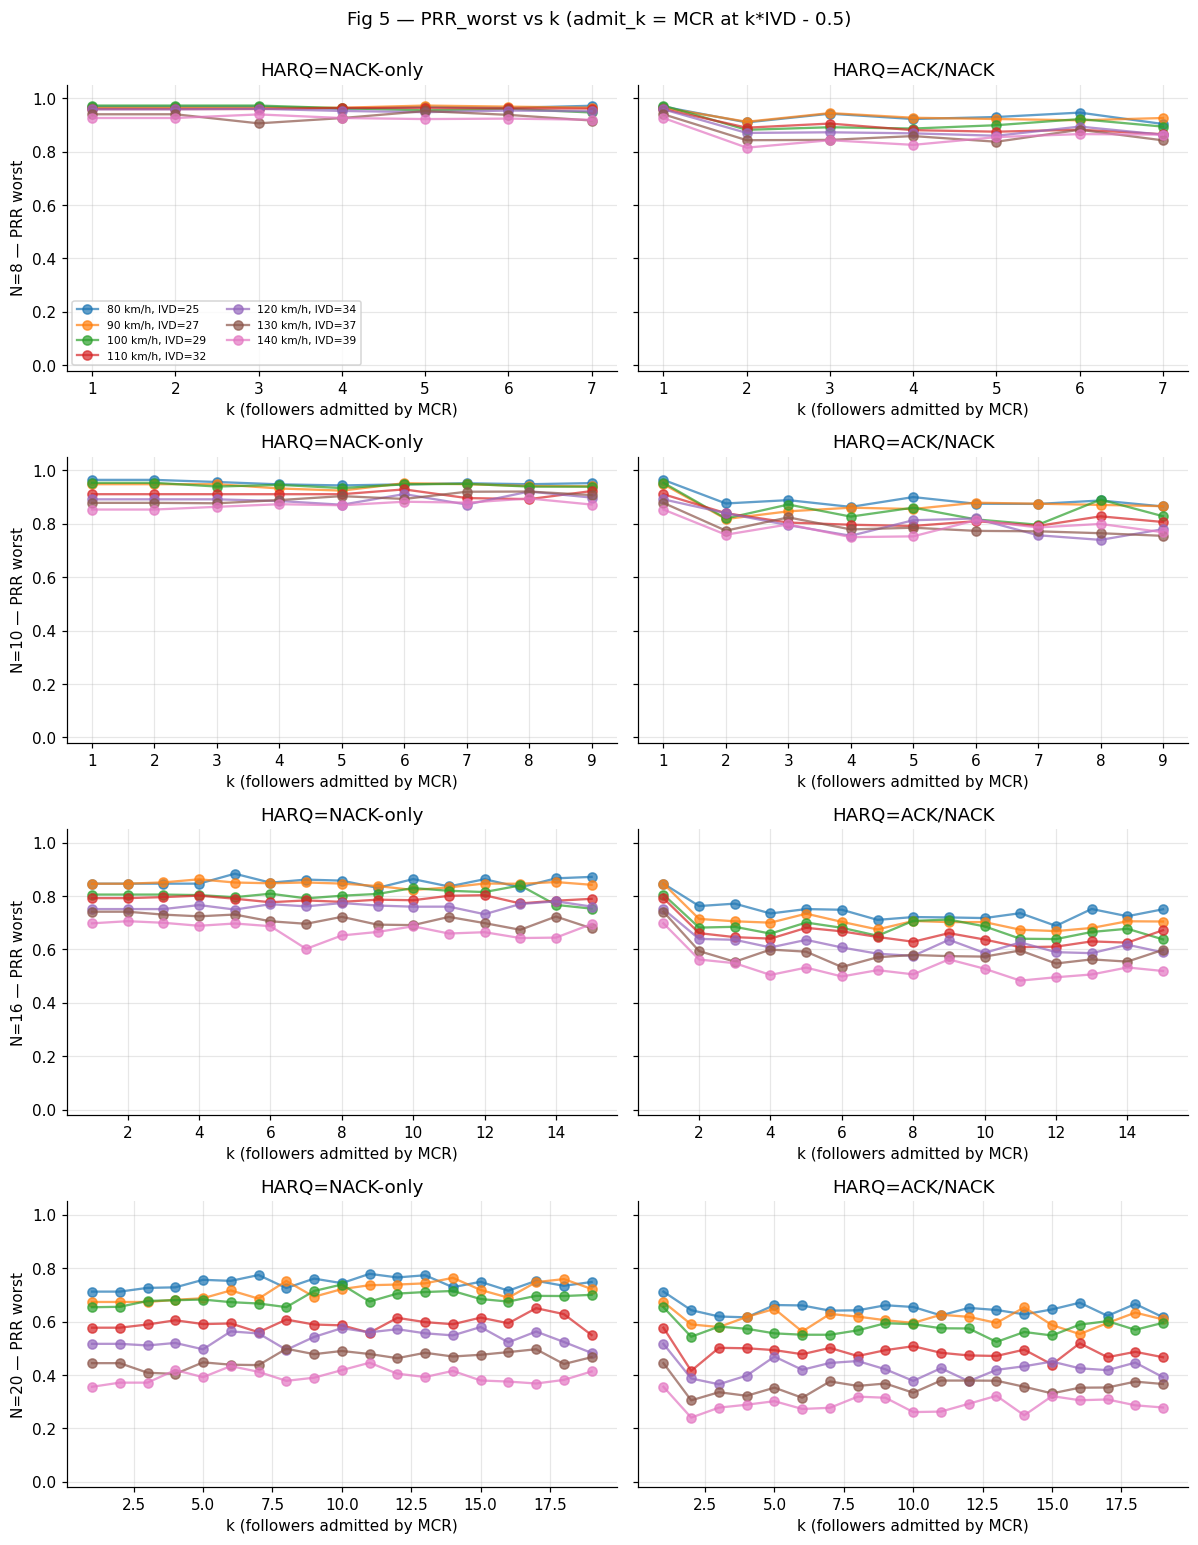

In [6]:
fig, axes = plt.subplots(len(ns), len(harqs), figsize=(5.5 * len(harqs), 3.5 * len(ns)), sharey=True, squeeze=False)
for i, N in enumerate(ns):
    for j, harq in enumerate(harqs):
        ax = axes[i, j]
        sub = df[(df["N"] == N) & (df["harq"] == harq)]
        # Keep only the admit_k rows (not admit_0 / admit_all)
        sub = sub[sub["mcr_label"].str.startswith("admit_") & (sub["mcr_label"] != "admit_0") & (sub["mcr_label"] != "admit_all")].copy()
        sub["k"] = sub["mcr_label"].str.replace("admit_", "").astype(int)
        for (spd, ivd), g in sub.groupby(["speed", "ivd"]):
            g = g.sort_values("k")
            ax.plot(g["k"], g["prr_worst_mean"], marker="o",
                    label=f"{spd} km/h, IVD={ivd}", alpha=0.7)
        ax.set_xlabel("k (followers admitted by MCR)")
        if j == 0:
            ax.set_ylabel(f"N={N} — PRR worst")
        ax.set_title(f"HARQ={'NACK-only' if harq==1 else 'ACK/NACK'}")
        ax.set_ylim(-0.02, 1.05)
        if i == 0 and j == 0:
            ax.legend(fontsize=7, ncol=2)
fig.suptitle("Fig 5 — PRR_worst vs k (admit_k = MCR at k*IVD - 0.5)", y=1.00)
fig.tight_layout()
out = RESULTS / "fig5_prr_worst_vs_k.png"
fig.savefig(out, bbox_inches="tight")
print(f"Saved {out}")
plt.show()

## Section 6 — Delta vs relay (if relay_storm_eval results are available)

If the user has a `results_relay_storm_eval/regime_aggregate.csv` (or `relay_l2id_compare/l2id_results.csv`) somewhere on disk, this section joins our baseline onto the relay PRR_worst at the SAME (speed, ivd, mcd) operating point and computes the delta. The headline hypothesis: relays help when the MCD gate is tight (`mcd < (N-1)*IVD`) and harm when the gate is loose (resource collisions dominate).

In [7]:
# Try common paths
candidate_paths = [
    NB_DIR.parent / "relay_storm_eval" / "results_regime_study" / "regime_aggregate.csv",
    NB_DIR.parent / "relay_l2id_compare" / "results_c4_campaign" / "headtohead_aggregate.csv",
    NB_DIR.parent / "relay_storm_eval" / "results" / "regime_aggregate.csv",
]
relay_csv = None
for p in candidate_paths:
    if p.exists():
        relay_csv = p
        break
if relay_csv is None:
    print("No relay results CSV found. Section 6 skipped (set relay_csv manually).")
else:
    rel = pd.read_csv(relay_csv)
    print(f"Loaded relay data: {relay_csv} ({len(rel)} rows)")
    print(rel.columns.tolist()[:20])
    # Pick PRR_worst column (relay_storm uses 'prr_worst', relay_l2id_compare may use 'prr_worst_mean').
    prr_col = "prr_worst" if "prr_worst" in rel.columns else (
        "prr_worst_mean" if "prr_worst_mean" in rel.columns else None)
    if prr_col is None:
        print("WARNING: relay CSV has no prr_worst column; cannot join.")
    else:
        # Join on (speed, ivd, mcd == our mcr_m). Keep only the baseline (relay_node == 0) rows.
        base = rel[rel.get("is_baseline", rel.get("relay_node", 1) == 0)] if "is_baseline" in rel.columns or "relay_node" in rel.columns else rel
        base = base[["speed", "ivd", "mcd", prr_col]].rename(columns={"mcd": "mcr_m", prr_col: "prr_relay_worst"})
        merged = df.merge(base, on=["speed", "ivd", "mcr_m"], how="inner")
        if len(merged) == 0:
            print("No matching (speed, ivd, mcr) tuples after join — datasets may be on different grids.")
        else:
            merged["delta_prr_worst"] = merged["prr_worst_mean"] - merged["prr_relay_worst"]
            fig, ax = plt.subplots(figsize=(7.5, 4.4))
            for N in ns:
                for harq in harqs:
                    sub = merged[(merged["N"] == N) & (merged["harq"] == harq)]
                    if len(sub) == 0:
                        continue
                    g = sub.groupby("mcr_m")["delta_prr_worst"].mean().reset_index().sort_values("mcr_m")
                    ax.plot(g["mcr_m"], g["delta_prr_worst"],
                            marker="o",
                            label=f"N={N}, h={'NACK-only' if harq==1 else 'ACK/NACK'}")
            ax.axhline(0, color="k", linestyle=":", alpha=0.5)
            ax.set_xlabel("MCR (m)")
            ax.set_ylabel("Δ PRR worst (baseline − relay_storm baseline)")
            ax.set_title("Fig 6 — Single-hop baseline vs relay-storm baseline")
            ax.legend(fontsize=8, ncol=2)
            fig.tight_layout()
            out = RESULTS / "fig6_delta_vs_relay.png"
            fig.savefig(out, bbox_inches="tight")
            print(f"Saved {out}")
            plt.show()
            merged.to_csv(RESULTS / "baseline_vs_relay_join.csv", index=False)
            print(f"Wrote join to {RESULTS / 'baseline_vs_relay_join.csv'}")

No relay results CSV found. Section 6 skipped (set relay_csv manually).


## Section 7 — Headline summary table

One row per (N, harq) summarizing the campaign.

In [8]:
summary = df.groupby(["N", "harq"]).agg(
    n_cells=("mcr_m", "count"),
    prr_worst_mean=pd.NamedAgg(column="prr_worst_mean", aggfunc="mean"),
    prr_worst_min=pd.NamedAgg(column="prr_worst_mean", aggfunc="min"),
    pir_worst_ms_mean=pd.NamedAgg(column="pir_worst_ms_mean", aggfunc="mean"),
    pir_worst_ms_max=pd.NamedAgg(column="pir_worst_ms_mean", aggfunc="max"),
    aoi_mean_ms_mean=pd.NamedAgg(column="aoi_mean_ms", aggfunc="mean"),
    hd_total=pd.NamedAgg(column="hd_total", aggfunc="sum"),
    rc_total=pd.NamedAgg(column="rc_total", aggfunc="sum"),
    ce_total=pd.NamedAgg(column="ce_total", aggfunc="sum"),
).reset_index()
summary.insert(2, "harq_mode", summary["harq"].map({1: "NACK-only", 2: "ACK/NACK"}))
print(summary.to_string(index=False))
summary.to_csv(RESULTS / "headline_summary.csv", index=False)
print(f"\nWrote {RESULTS / 'headline_summary.csv'}")

 N  harq harq_mode  n_cells  prr_worst_mean  prr_worst_min  pir_worst_ms_mean  pir_worst_ms_max  aoi_mean_ms_mean  hd_total  rc_total  ce_total
 8     1 NACK-only       63        0.952407       0.906111         102.956150          106.0900         44.193721         0         0      4958
 8     2  ACK/NACK       63        0.900714       0.815111         107.396080          115.8812         48.712230         0         0      3965
10     1 NACK-only       77        0.915495       0.853667         106.154099          113.8306         47.063549         0         0     12942
10     2  ACK/NACK       77        0.833919       0.716000         113.595925          128.3338         54.096489         0         0     10175
16     1 NACK-only      119        0.776541       0.602223         121.158034          153.6808         57.170471         0         0     83734
16     2  ACK/NACK      119        0.653005       0.483333         143.465282          188.5072         71.224553         0         0   